# ДЗ до теми 8: детекція об'єктів у приміщенні

Студент: Фарід Джафарлі

Набір даних Indoor Objects Detection містить фото кімнат з розміткою у форматі YOLO. Класів 10: двері (door), відчинені двері (openedDoor), дверцята шафи (cabinetDoor), дверцята холодильника (refrigeratorDoor), вікно (window), стілець (chair), стіл (table), шафа (cabinet), диван (couch) і стовп (pole).

Мета: навчити модель, яка знаходить і розпізнає хоча б 3 з 10 класів, насамперед двері, стільці і столи.

## 1. Імпорт бібліотек

In [1]:
import subprocess
import sys
from pathlib import Path

try:
    import ultralytics
except ImportError:  # Kaggle and Colab do not have it preinstalled
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'])
    import ultralytics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from IPython.display import Image as ShowImage, display
from PIL import Image, ImageDraw
from ultralytics import YOLO

print('ultralytics', ultralytics.__version__, '| torch', torch.__version__)

ultralytics 8.4.163 | torch 2.14.0


## 2. Робоче середовище

Я виконую завдання на своєму комп'ютері з GPU Apple M2 Max (у PyTorch це пристрій mps). Той самий код без змін працює в Kaggle Notebooks або Google Colab з GPU: там він вибере CUDA.

На Apple GPU оцінку моделі я запускаю на процесорі, бо на mps підрахунок метрик після навчання іноді дає збої.

In [2]:
if torch.cuda.is_available():
    DEVICE, EVAL_DEVICE = 0, 0
    print('GPU:', torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    DEVICE, EVAL_DEVICE = 'mps', 'cpu'
    print('GPU: Apple Silicon (mps)')
else:
    DEVICE, EVAL_DEVICE = 'cpu', 'cpu'
    print('GPU немає, навчання буде дуже повільним')

GPU: Apple Silicon (mps)


## 3. Підготовка даних

Дані вже поділені на навчальну (train), валідаційну (valid) і тестову (test) частини. Ноутбук шукає набір даних у локальній папці data, потім серед підключених даних Kaggle, а якщо не знаходить, завантажує його з Kaggle.

In [3]:
def find_dataset_root():
    candidates = [Path('data')]
    if Path('/kaggle/input').exists():
        candidates += [p.parent for p in Path('/kaggle/input').rglob('data.yaml')]
    for root in candidates:
        if all((root / split / 'images').exists() for split in ('train', 'valid', 'test')):
            return root.resolve()
    import kagglehub
    return Path(kagglehub.dataset_download('thepbordin/indoor-object-detection'))


DATA_ROOT = find_dataset_root()
CLASS_NAMES = list(yaml.safe_load(open(DATA_ROOT / 'data.yaml'))['names'])
print('Дані:', DATA_ROOT)
print('Класи:', CLASS_NAMES)

Дані: /Users/faridjafarli/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1
Класи: ['door', 'cabinetDoor', 'refrigeratorDoor', 'window', 'chair', 'table', 'cabinet', 'couch', 'openedDoor', 'pole']


## 4. Знайомство з даними

Кожному зображенню відповідає текстовий файл з розміткою. Один рядок у ньому описує один об'єкт: номер класу і координати рамки (центр, ширина, висота) у частках від розміру зображення.

In [4]:
def read_labels(split):
    rows = []
    for img in sorted((DATA_ROOT / split / 'images').iterdir()):
        label = DATA_ROOT / split / 'labels' / (img.stem + '.txt')
        lines = label.read_text().split('\n') if label.exists() else []
        for line in lines:
            if line.strip():
                c, x, y, w, h = line.split()[:5]
                rows.append({'split': split, 'image': img.name, 'class': CLASS_NAMES[int(c)],
                             'x': float(x), 'y': float(y), 'w': float(w), 'h': float(h)})
    return rows


labels = pd.DataFrame(read_labels('train') + read_labels('valid') + read_labels('test'))
for split in ('train', 'valid', 'test'):
    n_img = sum(1 for _ in (DATA_ROOT / split / 'images').iterdir())
    print(f'{split}: {n_img} зображень, {(labels["split"] == split).sum()} об\'єктів')

counts = labels.pivot_table(index='class', columns='split', values='image', aggfunc='count', fill_value=0)
counts = counts[['train', 'valid', 'test']].sort_values('train', ascending=False)
counts

train: 1012 зображень, 5492 об'єктів
valid: 230 зображень, 1289 об'єктів
test: 107 зображень, 550 об'єктів


split,train,valid,test
class,,,
cabinetDoor,3178,765,179
refrigeratorDoor,689,192,2
door,479,97,34
window,403,91,63
table,228,40,47
chair,204,49,87
cabinet,179,32,52
openedDoor,78,13,20
couch,27,1,58


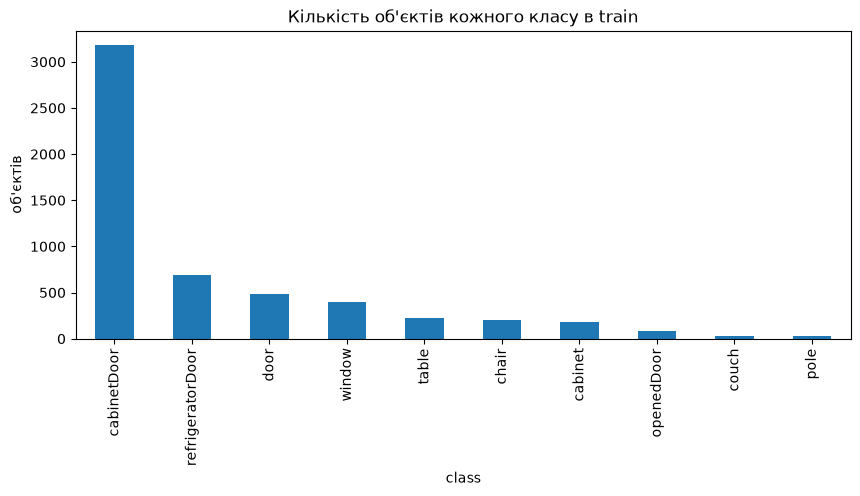

In [5]:
counts['train'].plot.bar(figsize=(10, 4), title="Кількість об'єктів кожного класу в train")
plt.ylabel("об'єктів")
plt.show()

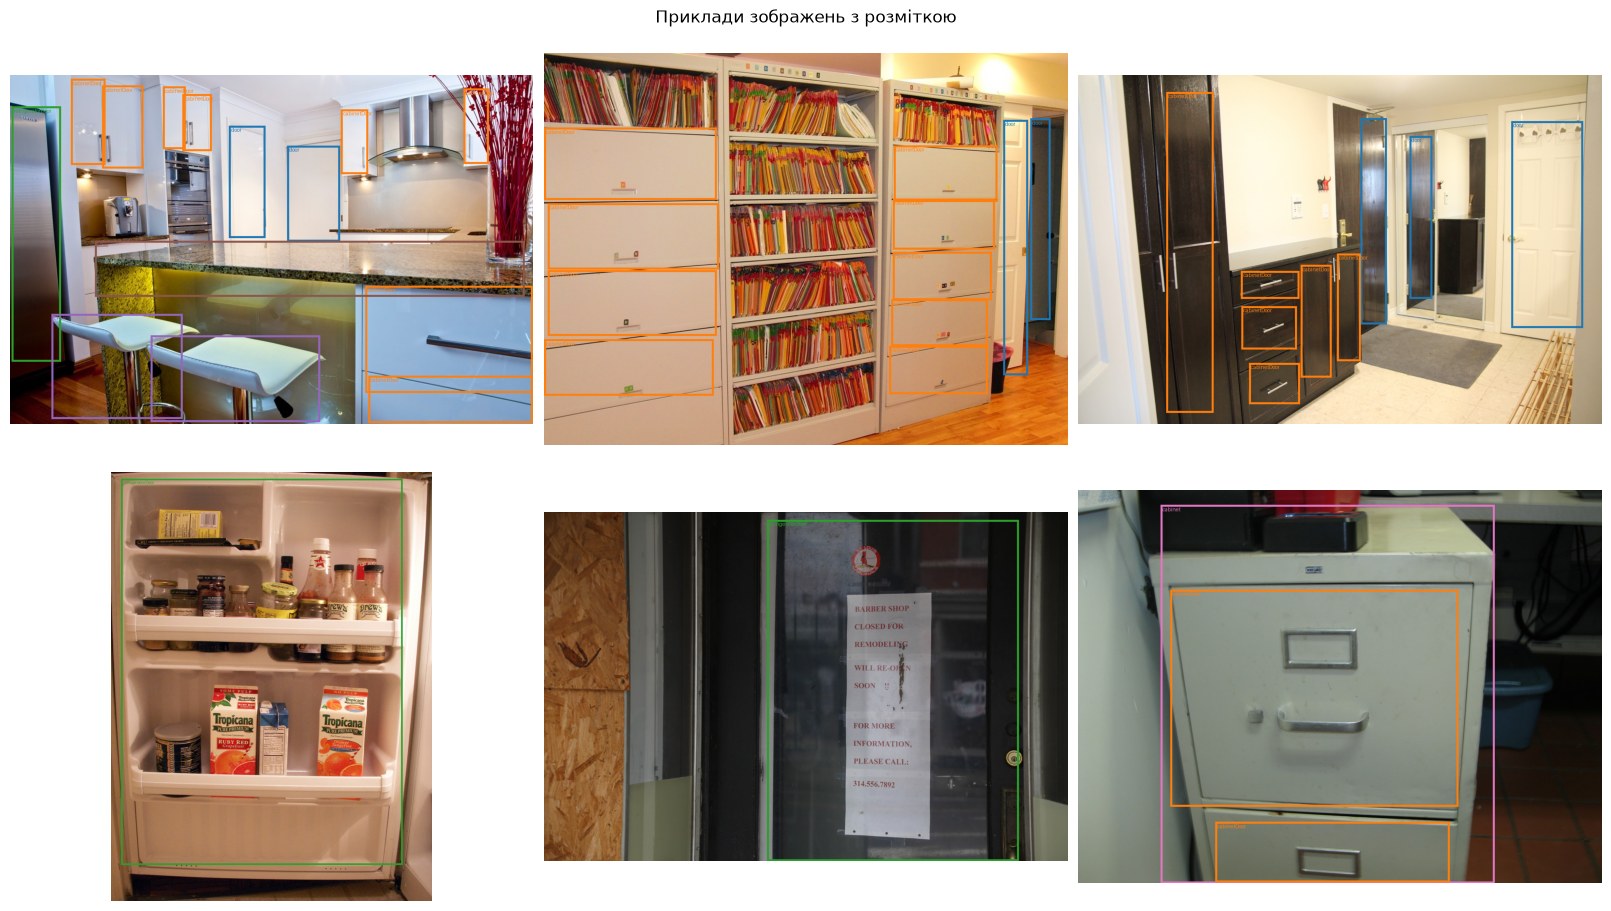

In [6]:
colors = plt.cm.tab10.colors
train_images = labels[labels['split'] == 'train']['image'].unique()
examples = np.random.default_rng(42).choice(train_images, 6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(16, 9), layout='constrained')
for ax, name in zip(axes.ravel(), examples):
    img = Image.open(DATA_ROOT / 'train' / 'images' / name).convert('RGB')
    draw = ImageDraw.Draw(img)
    W, H = img.size
    for _, r in labels[(labels['split'] == 'train') & (labels['image'] == name)].iterrows():
        color = tuple(int(255 * v) for v in colors[CLASS_NAMES.index(r['class'])])
        box = [(r.x - r.w / 2) * W, (r.y - r.h / 2) * H, (r.x + r.w / 2) * W, (r.y + r.h / 2) * H]
        draw.rectangle(box, outline=color, width=4)
        draw.text((box[0] + 4, box[1] + 2), r['class'], fill=color)
    ax.imshow(img)
    ax.axis('off')
fig.suptitle('Приклади зображень з розміткою')
plt.show()

Що видно з даних:
- у train 1012 зображень і 5492 об'єкти, у valid 230 зображень, у test 107;
- на одному фото в середньому більше 5 об'єктів;
- класи дуже нерівні: дверцят шаф (cabinetDoor) у train 3178, це більше половини всіх об'єктів, а диванів і стовпів лише по 27. У valid є всього один диван.

Отже, для частих класів у моделі буде багато прикладів, а для рідкісних майже нічого.

## 5. Конфігурація YOLO

Ultralytics читає опис набору даних з файлу YAML: шлях до даних, папки зображень для кожної частини, кількість класів і їхні назви.

Модель я беру YOLOv9s, як радить завдання. Вона невелика (близько 7 млн параметрів), тож швидко вчиться, але точна. Її вже навчили на наборі COCO, де є схожі класи (стілець, диван, стіл, холодильник), тому вона швидше звикне до нових даних.

In [7]:
DATA_YAML = Path('data.yaml').resolve()
config = {'path': str(DATA_ROOT), 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
          'nc': len(CLASS_NAMES), 'names': CLASS_NAMES}
DATA_YAML.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False))
print(DATA_YAML.read_text())

path: /Users/faridjafarli/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1
train: train/images
val: valid/images
test: test/images
nc: 10
names:
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole



## 6. Навчання моделі

Параметри навчання:
- 40 епох: попередньо навчена модель досягає найкращих метрик на валідації ще до кінця навчання, а найкращі ваги Ultralytics зберігає окремо;
- зупинка, якщо 15 епох поспіль метрики на валідації не покращуються;
- розмір зображень 640, стандартний для YOLO;
- батч 16: добре вміщується в пам'ять GPU;
- оптимізатор і швидкість навчання Ultralytics підбирає сам, аугментації стандартні.

Під час навчання Ultralytics після кожної епохи виводить втрати і метрики на валідації.

In [8]:
RUNS = Path('runs').resolve()
model = YOLO('yolov9s.pt')
model.train(data=str(DATA_YAML), epochs=40, patience=15, imgsz=640, batch=16, device=DEVICE,
            seed=42, deterministic=False, cache='ram', project=str(RUNS), name='train', exist_ok=True)

New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.163 🚀 Python-3.12.3 torch-2.14.0 MPS (Apple M2 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/faridjafarli/GitHub/goit-hw/dl_computer_vision/hw03-indoor-object-detection/data.yaml, degrees=0.0, deterministic=False, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, m

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x33d0a9580>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0470

In [9]:
BEST = RUNS / 'train' / 'weights' / 'best.pt'
print('Ваги збережено:', BEST, f'({BEST.stat().st_size / 1e6:.1f} МБ)')

Ваги збережено: /Users/faridjafarli/GitHub/goit-hw/dl_computer_vision/hw03-indoor-object-detection/runs/train/weights/best.pt (15.2 МБ)


## 7. Аналіз результатів

### 7.1 Графіки навчання

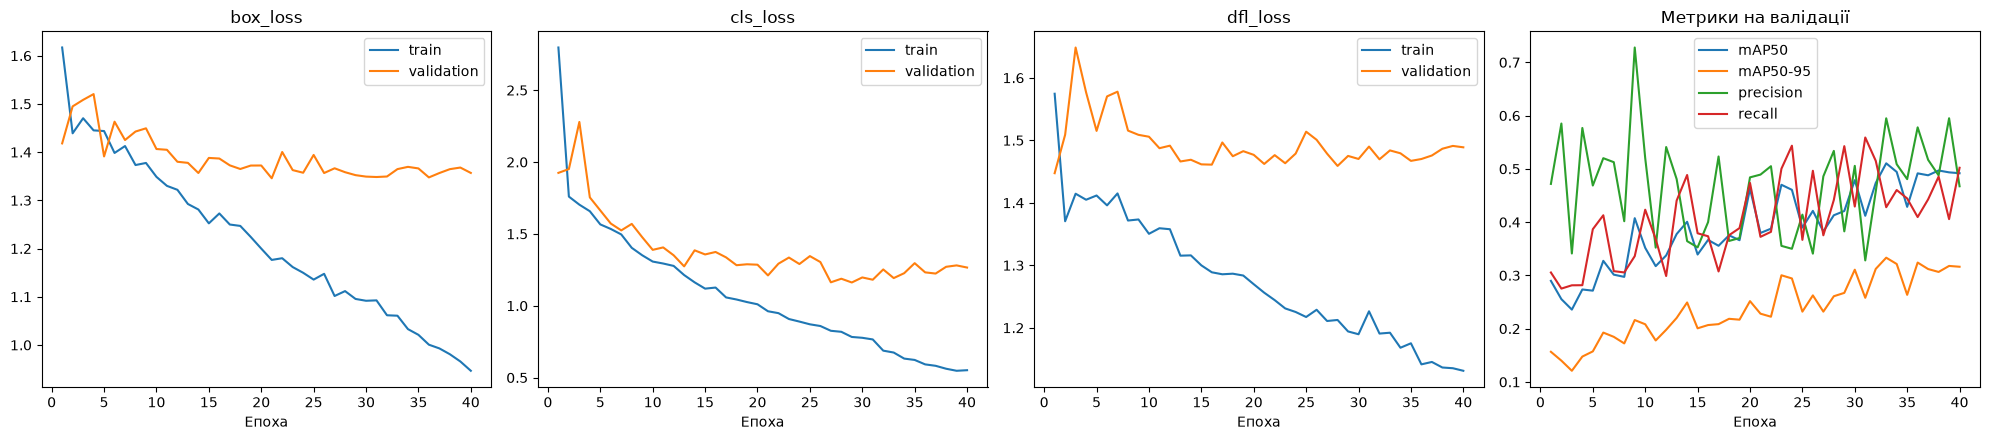

Найкраща епоха за mAP50-95: 33


In [10]:
hist = pd.read_csv(RUNS / 'train' / 'results.csv')
hist.columns = hist.columns.str.strip()

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, loss in zip(axes[:3], ['box_loss', 'cls_loss', 'dfl_loss']):
    ax.plot(hist['epoch'], hist[f'train/{loss}'], label='train')
    ax.plot(hist['epoch'], hist[f'val/{loss}'], label='validation')
    ax.set_title(loss)
    ax.set_xlabel('Епоха')
    ax.legend()
for col, label in [('metrics/mAP50(B)', 'mAP50'), ('metrics/mAP50-95(B)', 'mAP50-95'),
                   ('metrics/precision(B)', 'precision'), ('metrics/recall(B)', 'recall')]:
    axes[3].plot(hist['epoch'], hist[col], label=label)
axes[3].set_title('Метрики на валідації')
axes[3].set_xlabel('Епоха')
axes[3].legend()
plt.tight_layout()
plt.show()
print('Найкраща епоха за mAP50-95:', int(hist.loc[hist['metrics/mAP50-95(B)'].idxmax(), 'epoch']))

Втрати на навчальних даних падають до кінця навчання. Втрати на валідації спочатку теж падають, а приблизно після 20 епохи майже не змінюються. Розрив між ними поступово росте, тобто модель починає трохи перенавчатися. Сильного перенавчання немає, бо метрики на валідації не падають.

mAP50 на валідації росте приблизно до 0.5 і далі коливається. Коливання помітні, бо валідаційних фото небагато, а рідкісних класів там лише кілька штук. Найкращою стала 33 епоха, її ваги збережено в best.pt.

### 7.2 Метрики на валідаційному наборі

In [11]:
best_model = YOLO(BEST)
val = best_model.val(data=str(DATA_YAML), split='val', imgsz=640, device=EVAL_DEVICE,
                     batch=1 if EVAL_DEVICE == 'cpu' else 16, project=str(RUNS), name='val', exist_ok=True)
print(f'precision {val.box.mp:.3f} | recall {val.box.mr:.3f} | mAP50 {val.box.map50:.3f} | mAP50-95 {val.box.map:.3f}')

Ultralytics 8.4.163 🚀 Python-3.12.3 torch-2.14.0 CPU (Apple M2 Max)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 647.4±416.7 MB/s, size: 272.2 KB)
val: Scanning /Users/faridjafarli/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1/valid/labels.cache... 230 images, 31 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 230/230 107.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 230/230 4.8it/s 48.0s
                   all        230       1289      0.546      0.447      0.507      0.331
                  door         63         97      0.597      0.577      0.575      0.364
           cabinetDoor         99        765      0.796      0.775      0.797      0.448
      refrigeratorDoor         85        192      0.849      0.661      0.772      0.525
                window         39         91      0.452      0.253   

На валідації mAP50 0.507 і mAP50-95 0.331. Це в межах орієнтиру із завдання: mAP50 від 40 до 60%, mAP50-95 від 25 до 40%. Precision 0.546, recall 0.447: коли модель щось знаходить, вона здебільшого права, але пропускає більше половини об'єктів.

### 7.3 Результати для кожного класу

In [12]:
per_class = pd.DataFrame({
    'клас': [CLASS_NAMES[i] for i in val.box.ap_class_index],
    "об'єктів у valid": [counts.loc[CLASS_NAMES[i], 'valid'] for i in val.box.ap_class_index],
    'precision': val.box.p, 'recall': val.box.r, 'F1': val.box.f1,
    'mAP50': val.box.ap50, 'mAP50-95': val.box.ap,
}).sort_values('F1', ascending=False).reset_index(drop=True).round(3)
per_class

,клас,об'єктів у valid,precision,recall,F1,mAP50,mAP50-95
0,cabinetDoor,765,0.796,0.775,0.785,0.797,0.448
1,refrigeratorDoor,192,0.849,0.661,0.744,0.772,0.525
2,couch,1,0.584,1.000,0.737,0.995,0.896
3,chair,49,0.779,0.510,0.617,0.693,0.364
4,door,97,0.597,0.577,0.587,0.575,0.364
5,cabinet,32,0.524,0.438,0.477,0.494,0.318
6,window,91,0.452,0.253,0.324,0.294,0.177
7,table,40,0.312,0.150,0.203,0.171,0.091
8,pole,9,0.564,0.111,0.186,0.231,0.106
9,openedDoor,13,0.000,0.000,0.000,0.052,0.025


Найкраще модель розпізнає дверцята шаф (F1 0.785), дверцята холодильника (0.744), стільці (0.617) і двері (0.587). Дверцят шаф і холодильників у навчальних даних найбільше. Диван має високі метрики, але у valid він лише один, тому цим числам довіряти не можна.

Найгірше модель працює з відчиненими дверима (F1 0), стовпами (0.186), столами (0.203) і вікнами (0.324). Відчинених дверей і стовпів у train менше сотні.

### 7.4 Матриця помилок

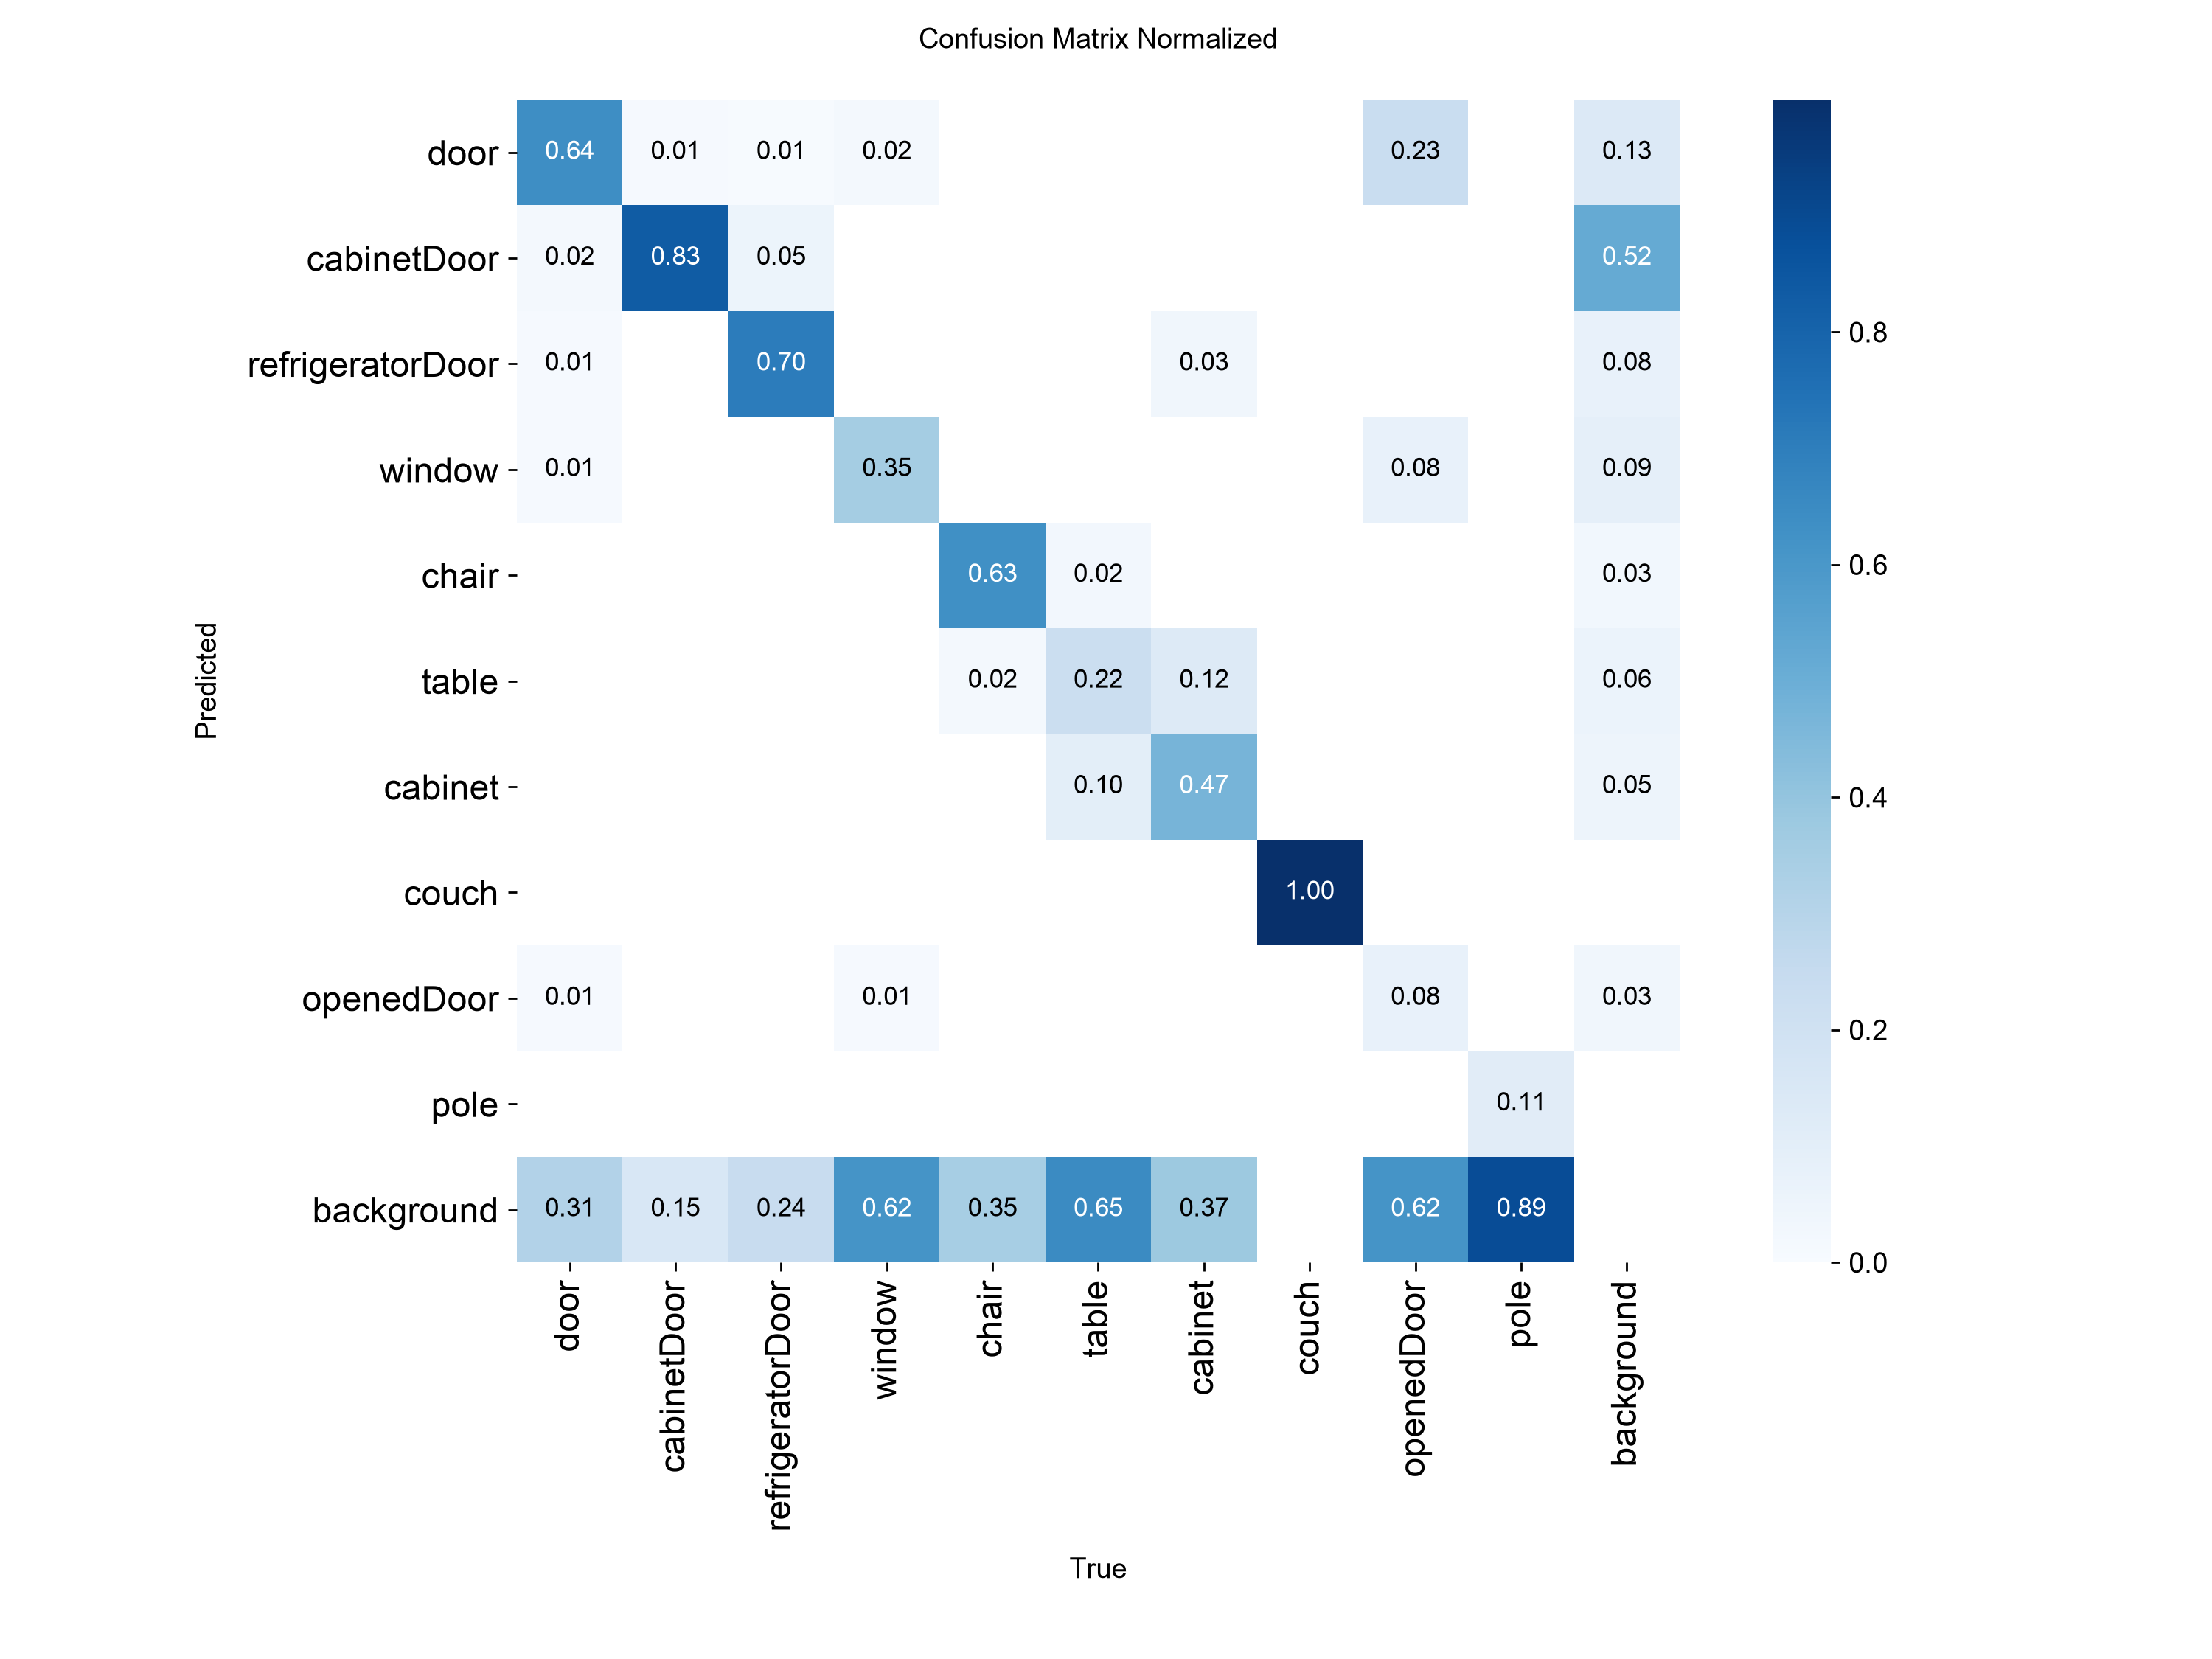

,фактичний клас,прогноз,кількість
0,refrigeratorDoor,cabinetDoor,10
1,cabinetDoor,door,8
2,cabinet,table,4
3,table,cabinet,4
4,openedDoor,door,3
5,cabinetDoor,refrigeratorDoor,3


In [13]:
display(ShowImage(filename=str(RUNS / 'val' / 'confusion_matrix_normalized.png'), width=850))

matrix = val.confusion_matrix.matrix  # rows: predicted class, columns: true class, last index: background
pairs = [(CLASS_NAMES[t], CLASS_NAMES[p], int(matrix[p, t]))
         for t in range(len(CLASS_NAMES)) for p in range(len(CLASS_NAMES)) if p != t and matrix[p, t] > 0]
pd.DataFrame(pairs, columns=['фактичний клас', 'прогноз', 'кількість']) \
    .sort_values('кількість', ascending=False).head(6).reset_index(drop=True)

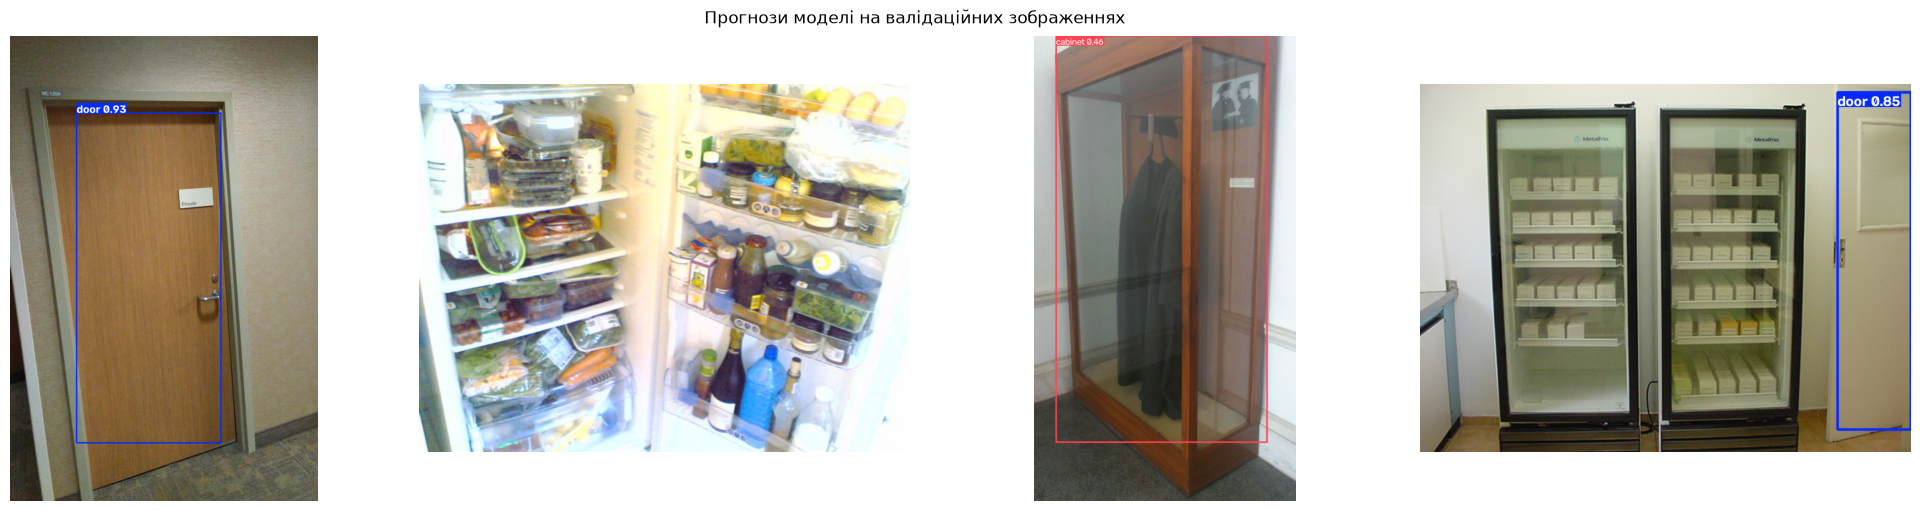

In [14]:
val_images = sorted((DATA_ROOT / 'valid' / 'images').iterdir())
sample = [val_images[i] for i in np.random.default_rng(1).choice(len(val_images), 4, replace=False)]
results = best_model.predict(sample, conf=0.25, imgsz=640, device=EVAL_DEVICE, verbose=False)
fig, axes = plt.subplots(1, 4, figsize=(20, 5), layout='constrained')
for ax, r in zip(axes, results):
    ax.imshow(r.plot()[..., ::-1])
    ax.axis('off')
fig.suptitle('Прогнози моделі на валідаційних зображеннях')
plt.show()

Найчастіше модель не плутає класи між собою, а просто не помічає об'єкт. У матриці помилок це рядок background: так модель пропускає 65% столів, 62% вікон, 62% відчинених дверей і 89% стовпів.

Серед помилок між класами найчастіші такі:
- дверцята холодильника модель приймає за дверцята шафи, бо вони схожі за формою;
- відчинені двері вона часто називає просто дверима (23% відчинених дверей), адже це той самий предмет в іншому положенні;
- столи і шафи модель плутає в обидва боки, бо це великі прямокутні меблі.

На прикладах прогнозів видно, що звичайні двері модель знаходить впевнено, а на фото з холодильниками дверцят холодильника не знаходить.

## 8. Висновки і рекомендації

- YOLOv9s, донавчена за 40 епох, дає на валідації mAP50 0.507 і mAP50-95 0.331. Це в межах очікуваного результату.
- Мету досягнуто: модель надійно знаходить 4 класи з 10, у них mAP50 і F1 вищі за 0.5. Це дверцята шаф, дверцята холодильника, стільці і двері. Столи вона поки розпізнає погано.
- Головна проблема не в плутанині класів, а в пропущених об'єктах, особливо рідкісних.

Що можна покращити:
- додати більше фото з рідкісними класами: відчиненими дверима, стовпами, диванами і столами;
- під час навчання частіше показувати фото з рідкісними класами або збільшити їхню вагу;
- об'єднати door і openedDoor, якщо для задачі не важливо, чи відчинені двері;
- навчати на більших зображеннях, наприклад 1024 замість 640, щоб модель краще бачила дрібні об'єкти;
- спробувати більшу модель, наприклад YOLOv9m, на потужному GPU в Kaggle або Colab.